# Residuals: the six Tspan-matched feather sets

All six share the same Tspan (raw LOFAR coverage window). Names encode both axes that matter -- station set and correction status:

- **`feathers_combined_uncorrected`** -- every station (LOFAR included), NOT DM(t)-corrected (NE_SW -> 0, DM1/DM2 left free). The reference.
- **`feathers_combined_corrected`** -- every station, SAME correction applied everywhere (LOFAR's own TOAs included -- its residuals there reflect how well the smoothed GP curve describes its own data, not the exact per-epoch fit anymore).
- **`feathers_highfreq_uncorrected`** -- high-freq stations only (GMRT included, LOFAR/NenuFAR excluded), NOT corrected.
- **`feathers_highfreq_corrected`** -- high-freq stations only, corrected.
- **`feathers_lofaronly_uncorrected`** -- LOFAR/NenuFAR only, NOT corrected.
- **`feathers_lofaronly_corrected`** -- LOFAR/NenuFAR only, corrected.

`highfreq_*` + `lofaronly_*` = `combined_*` (same TOAs, just split by station set). The plots below show each station split's uncorrected-vs-corrected overlay (combined / highfreq / lofaronly); the printed summary gives std for all six.


In [1]:
import os
# Jupyter/VS Code sets the kernel's cwd to the notebook's own folder by
# default -- everything below assumes cwd == repo root (where scripts/,
# feathers_*/, samples/ etc. live), so step up out of notebooks/ if needed.
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
assert os.path.isdir("scripts"), f"expected repo root (with a scripts/ dir) as cwd, got {os.getcwd()}"

import numpy as np
import matplotlib.pyplot as plt
import discovery as ds

In [2]:
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": "#333333",
    "axes.labelcolor": "#222222",
    "axes.titlesize": 15,
    "axes.titleweight": "bold",
    "axes.labelsize": 12,
    "axes.linewidth": 0.9,
    "axes.grid": False,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "xtick.color": "#333333",
    "ytick.color": "#333333",
    "legend.fontsize": 9.5,
    "legend.frameon": True,
    "legend.framealpha": 0.9,
    "legend.edgecolor": "#333333",
    "legend.facecolor": "white",
    "font.family": "sans-serif",
    "font.size": 11,
    "savefig.dpi": 200,
    "savefig.facecolor": "white",
})
UNCORR_COLOR = "C0"   # combined_uncorrected
CORR_COLOR = "C1"     # combined_corrected
GROUP_MARKERS = {"LOFAR": "o", "Other telescopes": "s"}


def classify_group(sys_vals):
    sys_vals = np.asarray(sys_vals)
    return np.where(np.char.startswith(sys_vals, "LOFAR") | np.char.startswith(sys_vals, "DE60"),
                     "LOFAR", "Other telescopes")

In [3]:
PULSARS = ["J1012+5307", "J1640+2224", "J1744-1134"]
DATASETS = ["feathers_combined_uncorrected", "feathers_combined_corrected",
            "feathers_highfreq_uncorrected", "feathers_highfreq_corrected",
            "feathers_lofaronly_uncorrected", "feathers_lofaronly_corrected"]

loaded = {}
for name in PULSARS:
    loaded[name] = {d: ds.Pulsar.read_feather(f"{d}/{name}") for d in DATASETS}
print("loaded:", list(loaded.keys()))


loaded: ['J1012+5307', 'J1640+2224', 'J1744-1134']


In [4]:
PAIRS = [
    ("combined",  "feathers_combined_uncorrected",  "feathers_combined_corrected"),
    ("highfreq",  "feathers_highfreq_uncorrected",  "feathers_highfreq_corrected"),
    ("lofaronly", "feathers_lofaronly_uncorrected", "feathers_lofaronly_corrected"),
]


def plot_pair(name, psrs, label, unc_key, corr_key):
    uncorr = psrs[unc_key]
    corr = psrs[corr_key]

    mjd_u = uncorr.toas / 86400.0
    mjd_c = corr.toas / 86400.0
    res_u_us = uncorr.residuals * 1e6
    res_c_us = corr.residuals * 1e6
    group_u = classify_group(uncorr.flags.get("sys", [""] * len(uncorr.toas)))
    group_c = classify_group(corr.flags.get("sys", [""] * len(corr.toas)))

    fig, ax = plt.subplots(figsize=(12, 5))
    for g in np.unique(group_u):
        sel = group_u == g
        ax.scatter(mjd_u[sel], res_u_us[sel], s=8, c=UNCORR_COLOR, alpha=0.35,
                   marker=GROUP_MARKERS[g], label=f"{label}, uncorrected ({g})")
    for g in np.unique(group_c):
        sel = group_c == g
        ax.scatter(mjd_c[sel], res_c_us[sel], s=8, c=CORR_COLOR, alpha=0.5,
                   marker=GROUP_MARKERS[g], label=f"{label}, corrected ({g})")
    ax.axhline(0.0, color="#999999", lw=0.8, ls="--", zorder=0)
    ax.set_xlabel("MJD")
    ax.set_ylabel(r"Residual ($\mu$s)")
    ax.set_title(f"{name}: {label} dataset, uncorrected vs DM(t)-corrected")
    ax.legend(loc="upper left", ncol=2)
    fig.tight_layout()
    plt.show()


def print_summary(name, psrs):
    print(f"=== {name} ===")
    for d in DATASETS:
        psr = psrs[d]
        res_us = psr.residuals * 1e6
        group = classify_group(psr.flags.get("sys", [""] * len(psr.toas)))
        for g in np.unique(group):
            sel = group == g
            print(f"  {d:30s} {g:18s} n={sel.sum():6d}  std={res_us[sel].std():8.3f} us")


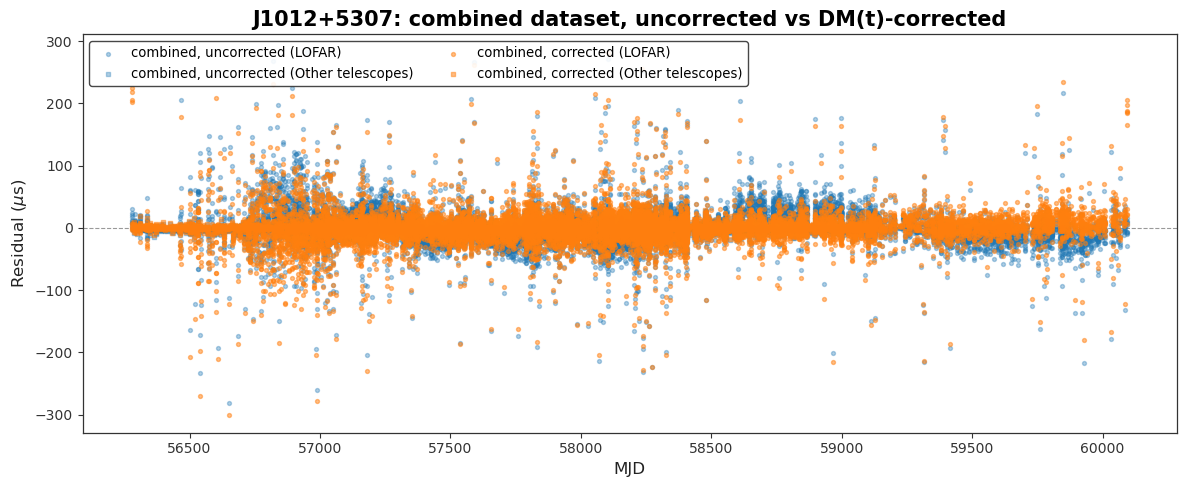

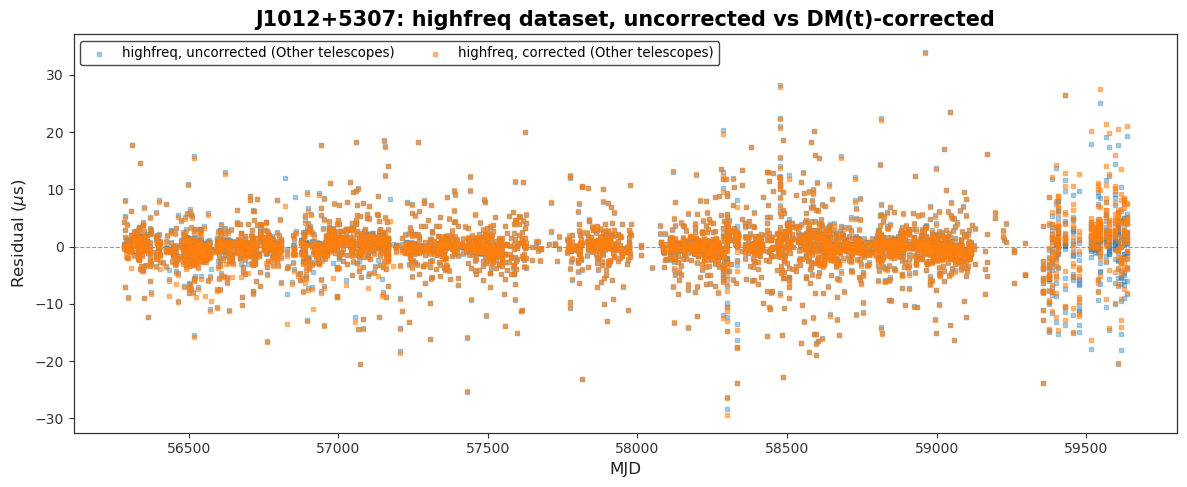

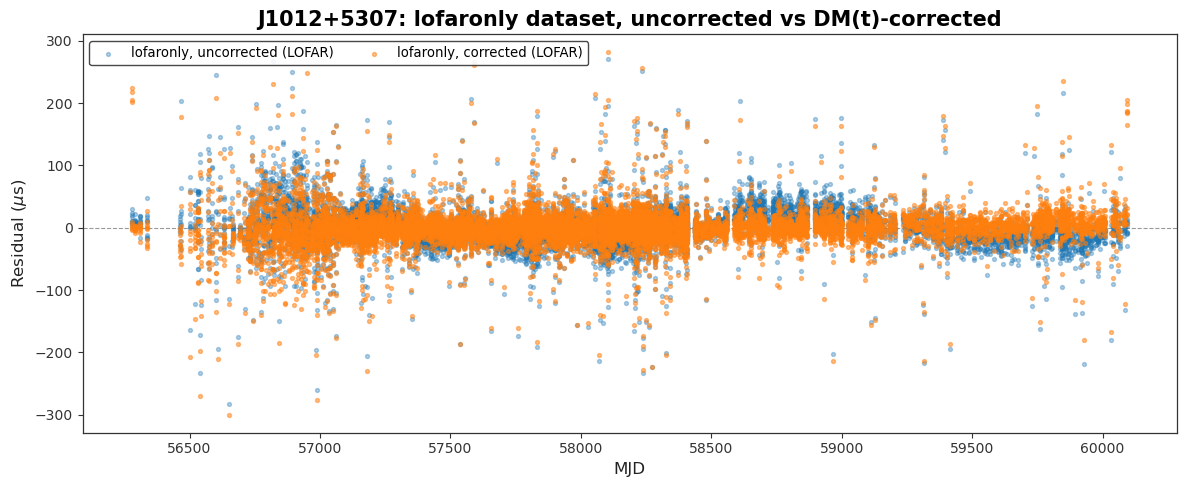

=== J1012+5307 ===
  feathers_combined_uncorrected  LOFAR              n= 14698  std=  29.152 us
  feathers_combined_uncorrected  Other telescopes   n=  3982  std=   4.314 us
  feathers_combined_corrected    LOFAR              n= 14698  std=  27.008 us
  feathers_combined_corrected    Other telescopes   n=  3982  std=   4.388 us
  feathers_highfreq_uncorrected  Other telescopes   n=  3982  std=   4.314 us
  feathers_highfreq_corrected    Other telescopes   n=  3982  std=   4.388 us
  feathers_lofaronly_uncorrected LOFAR              n= 14698  std=  29.152 us
  feathers_lofaronly_corrected   LOFAR              n= 14698  std=  27.008 us



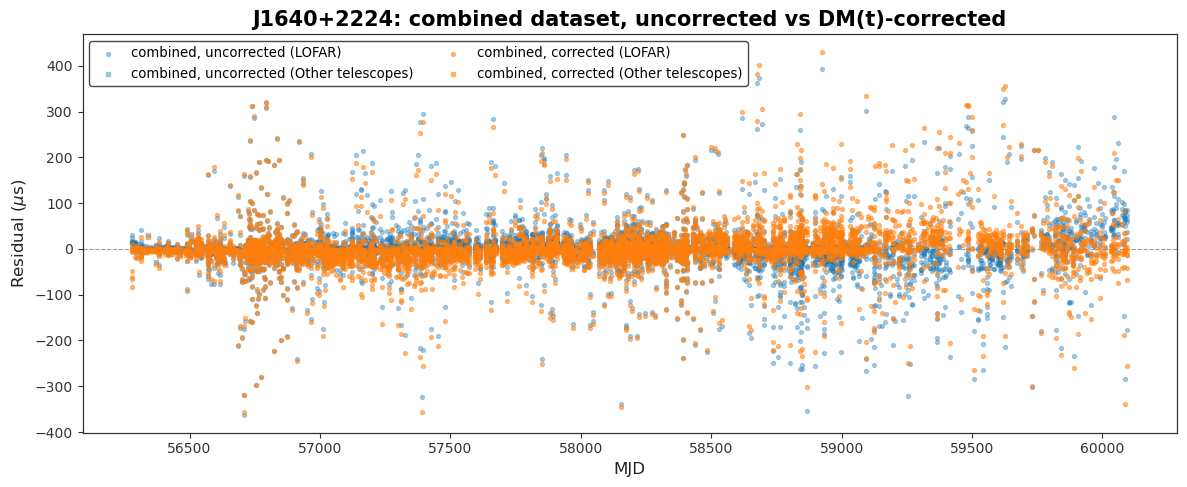

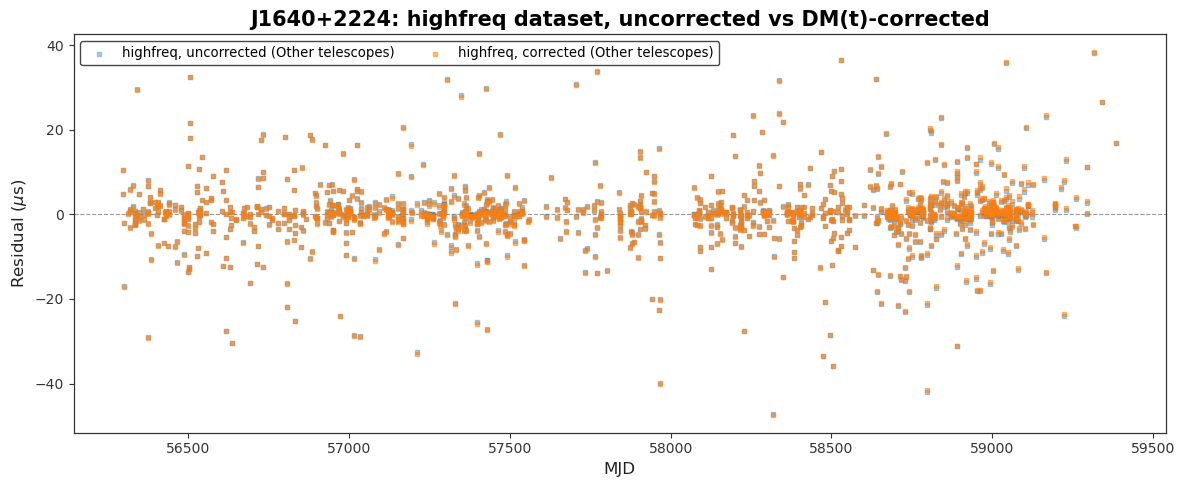

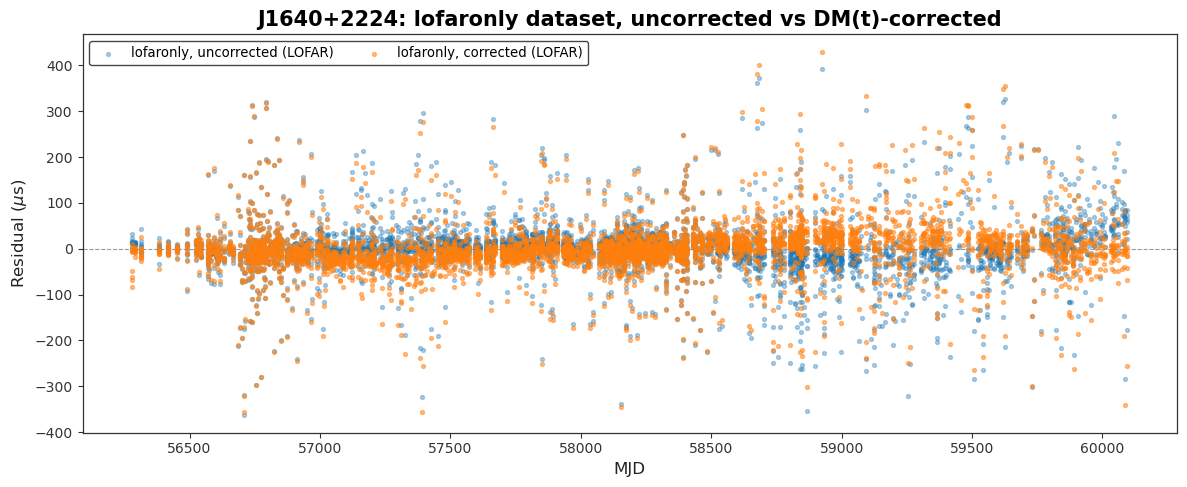

=== J1640+2224 ===
  feathers_combined_uncorrected  LOFAR              n=  5200  std=  56.122 us
  feathers_combined_uncorrected  Other telescopes   n=  1297  std=   7.666 us
  feathers_combined_corrected    LOFAR              n=  5200  std=  55.596 us
  feathers_combined_corrected    Other telescopes   n=  1297  std=   7.671 us
  feathers_highfreq_uncorrected  Other telescopes   n=  1297  std=   7.666 us
  feathers_highfreq_corrected    Other telescopes   n=  1297  std=   7.671 us
  feathers_lofaronly_uncorrected LOFAR              n=  5200  std=  56.122 us
  feathers_lofaronly_corrected   LOFAR              n=  5200  std=  55.596 us



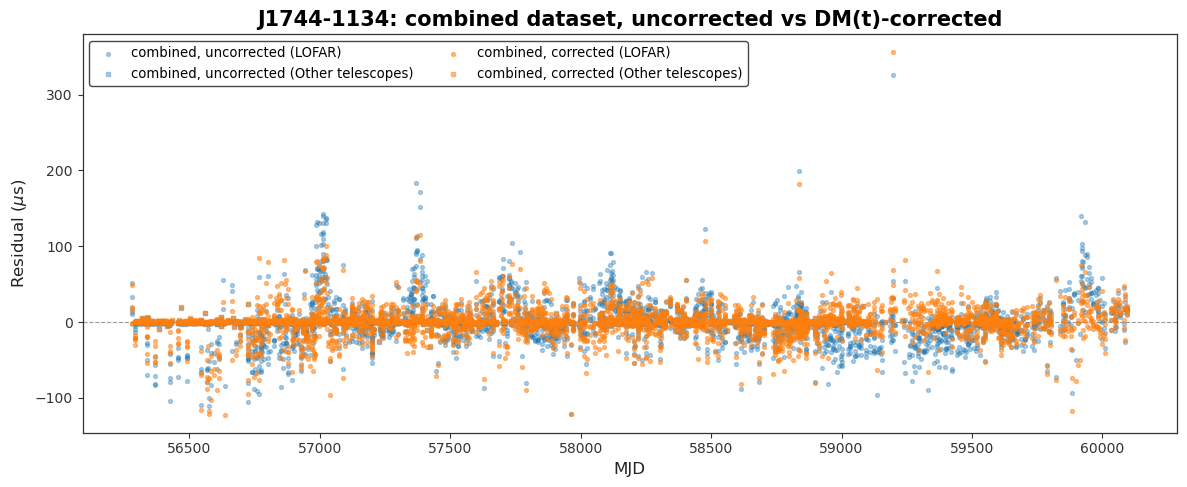

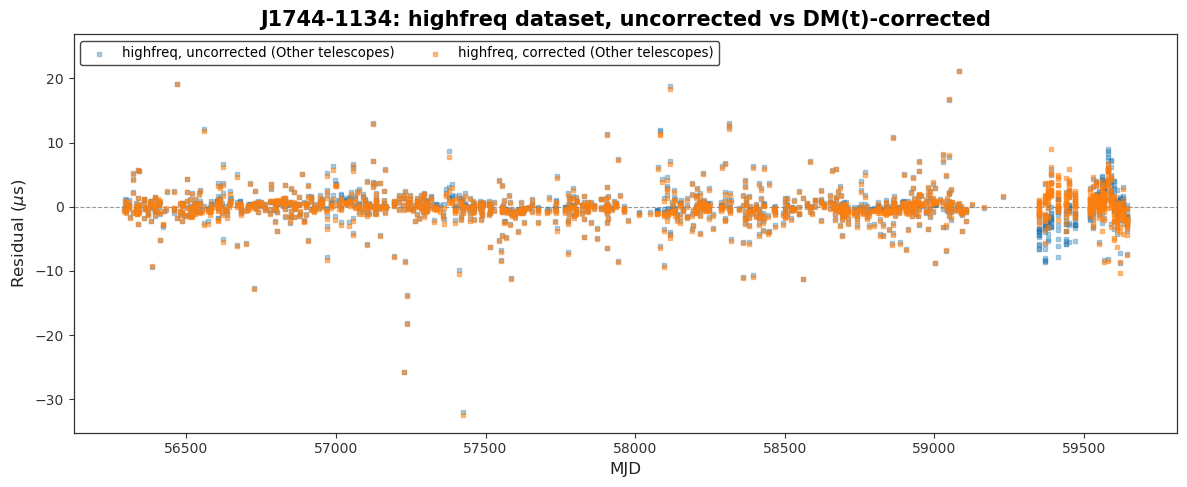

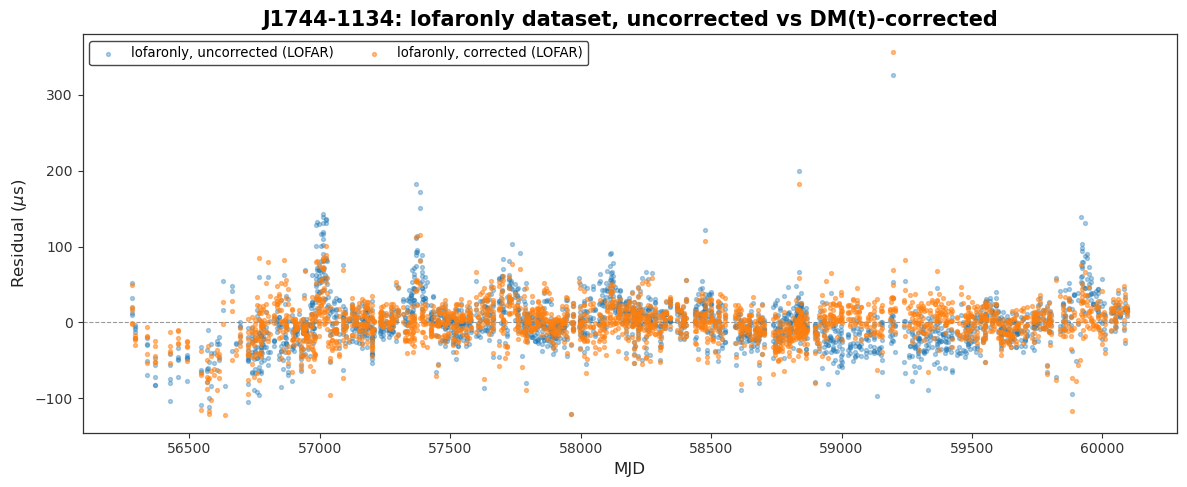

=== J1744-1134 ===
  feathers_combined_uncorrected  LOFAR              n=  2434  std=  32.763 us
  feathers_combined_uncorrected  Other telescopes   n=  1592  std=   2.995 us
  feathers_combined_corrected    LOFAR              n=  2434  std=  26.020 us
  feathers_combined_corrected    Other telescopes   n=  1592  std=   2.873 us
  feathers_highfreq_uncorrected  Other telescopes   n=  1592  std=   2.995 us
  feathers_highfreq_corrected    Other telescopes   n=  1592  std=   2.873 us
  feathers_lofaronly_uncorrected LOFAR              n=  2434  std=  32.763 us
  feathers_lofaronly_corrected   LOFAR              n=  2434  std=  26.020 us



In [5]:
for name in PULSARS:
    for label, unc_key, corr_key in PAIRS:
        plot_pair(name, loaded[name], label, unc_key, corr_key)
    print_summary(name, loaded[name])
    print()
